<a href="https://colab.research.google.com/github/athfizh/PCVK26_05_Hafizh/blob/main/Modul%206/P6_TugasPraktikum_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama  : Athaulla Hafizh

Absen : 05

Kelas : TI-3F

NIM   : 244107020030

**Modul 6 - Spasial Filter**

---

In [ ]:
# Sel Identitas
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Athaulla Hafizh'
NIM  = '244107020030'

N      = int(NIM[-3:])
PARAM = {
    'noise': round(0.05 + (N % 5) * 0.02, 2),   # kepadatan noise Salt and Pepper (Tugas 1)
    'blur' : 1.0 + (N % 3) * 0.5,                # sigma Gaussian untuk citra "sedikit buram" (Tugas 2)
    'blok' : 2 * (N % 3) + 7,                    # blockSize Adaptive Threshold, harus ganjil (Tugas 3)
    'seed' : N,                                  # seed acak agar hasil bisa diulang
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA  :', NAMA)
print('NIM   :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA  : Athaulla Hafizh
NIM   : 244107020030 | N = 30
noise  : 0.05
blur   : 1.0
blok   : 7
seed   : 30
WAKTU : 2026-09-29 13:33:02 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN : e43d43be5dc6d6fe


**Langkah Persiapan: Mount Google Drive, Import Library, dan Folder Kerja**

Folder CONTOH dan BASE ditentukan di awal. Folder CONTOH berisi citra contoh dari modul yaitu lena.jpg.jpeg, djawatan.jpg.jpeg, dan mandrill.tiff, sementara BASE diarahkan ke folder yang sama.

Fungsi muat_citra dipakai untuk membaca citra dari path tersebut, dan sudah menangani nama file yang berekstensi ganda seperti lena.jpg yang sebenarnya tersimpan sebagai lena.jpg.jpeg. Kalau file tidak ditemukan, fungsi ini otomatis memakai citra cadangan bawaan scikit-image supaya notebook tetap bisa dijalankan, dan akan muncul tanda [!]. Kalau berhasil ditemukan akan muncul tanda [OK].

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import library yang dibutuhkan
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math, os
from google.colab.patches import cv2_imshow
from PIL import Image as im

CONTOH = '/content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SPASIAL FILTER'   # lena.jpg.jpeg, djawatan.jpg.jpeg, mandrill.tiff
BASE   = '/content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SPASIAL FILTER'   # citra milik sendiri (jika ada)

print('CONTOH:', CONTOH)
print('BASE  :', BASE)


def cari_file(path):
    """Nama file di Drive bisa berekstensi ganda (mis. lena.jpg.jpeg). Fungsi ini mencoba beberapa kemungkinan."""
    for p in [path, path + '.jpeg', path + '.jpg', os.path.splitext(path)[0] + '.jpeg']:
        if os.path.exists(p):
            return p
    return None


def muat_citra(path, jenis='lena'):
    """Membaca citra BGR dari path (mendukung ekstensi ganda). Jika file tidak ditemukan di Drive,
    dipakai citra cadangan bawaan scikit-image agar seluruh notebook tetap bisa dijalankan."""
    ditemukan = cari_file(path)
    img = cv.imread(ditemukan) if ditemukan else None
    if img is None:
        from skimage import data
        cadangan = {'lena': data.astronaut, 'mandrill': data.chelsea, 'alam': data.coffee}
        print(f'[!] {os.path.basename(path)} tidak ditemukan, memakai citra cadangan ({jenis})')
        img = cv.cvtColor(cadangan[jenis](), cv.COLOR_RGB2BGR)
    else:
        print(f'[OK] {os.path.basename(ditemukan)} berhasil dimuat, ukuran {img.shape}')
    return img

Mounted at /content/drive
CONTOH: /content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SPASIAL FILTER
BASE  : /content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SPASIAL FILTER


---
# **D. Praktikum Filter**

**1. Fungsi konvolusi (sesuai algoritma Bagian C, tanpa library)**

Ada dua fungsi yang dibuat:
- `convolution2d_loop` : empat for bersarang, persis pseudocode modul. Dipakai untuk matriks kecil dan pembanding.
- `convolution2d` : rumus sama, tapi loop posisi piksel diganti irisan array NumPy supaya cepat untuk citra besar.

Parameter: citra, kernel, stride, padding (nilai pad diisi 0).

In [ ]:
def convolution2d_loop(image, kernel, stride=1, padding=0):
    """Versi paling dasar: empat for bersarang persis seperti pseudocode modul.
    Sangat lambat untuk citra besar, dipakai untuk matriks kecil dan sebagai pembanding."""
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    img = np.pad(np.asarray(image, dtype=np.float64), padding, mode='constant', constant_values=0)
    H, W = img.shape
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1
    hasil = np.zeros((out_h, out_w))
    for y in range(out_h):
        for x in range(out_w):
            total = 0.0
            for k1 in range(kh):
                for k2 in range(kw):
                    total += kernel[k1, k2] * img[y * stride + k1, x * stride + k2]
            hasil[y, x] = total
    return hasil


def convolution2d(image, kernel, stride=1, padding=0):
    """Fungsi konvolusi utama tanpa library konvolusi (tanpa cv.filter2D / cv.blur / dsb).
    Parameter: citra masukan, kernel, stride, dan nilai pad (diisi 0).
    Rumus tiap piksel sama dengan pseudocode modul: z(x,y) = z(x,y) + H(k1,k2) * Img(x+k1, y+k2).
    Bedanya, loop x dan y digantikan irisan array NumPy sehingga cepat untuk citra 512x512."""
    assert image.ndim == 2, 'Fungsi ini menerima citra keabuan (2 dimensi)'
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    img = np.pad(np.asarray(image, dtype=np.float64), padding, mode='constant', constant_values=0)
    H, W = img.shape
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1
    hasil = np.zeros((out_h, out_w))
    for k1 in range(kh):
        for k2 in range(kw):
            irisan = img[k1 : k1 + (out_h - 1) * stride + 1 : stride,
                         k2 : k2 + (out_w - 1) * stride + 1 : stride]
            hasil += kernel[k1, k2] * irisan
    return hasil

**2a. Verifikasi fungsi pada contoh matriks modul**

Uji fungsi pakai citra 5x5 dan kernel 3x3 dari Bagian C.2. Dibandingkan juga dengan cv.filter2D (cuma sebagai pembanding, bukan bagian dari fungsi buatan).

In [ ]:
# Matriks contoh dari modul (citra 5x5 dan kernel 3x3)
f = np.array([[4, 4, 3, 5, 4],
              [6, 6, 5, 5, 2],
              [5, 6, 6, 6, 2],
              [6, 7, 5, 5, 3],
              [3, 5, 2, 4, 4]])
g = np.array([[ 0, -1,  0],
              [-1,  4, -1],
              [ 0, -1,  0]])

# 1. Piksel pinggir diabaikan (padding = 0) -> hanya 3x3 piksel bagian dalam
hasil_valid = convolution2d_loop(f, g, stride=1, padding=0)
print('Konvolusi padding=0 (piksel pinggir diabaikan):')
print(hasil_valid.astype(int))

# 2. Pinggir diberi nilai 0 (padding = 1) -> ukuran hasil tetap 5x5
hasil_pad = convolution2d_loop(f, g, stride=1, padding=1)
print('\nKonvolusi padding=1 (pinggir bernilai 0):')
print(hasil_pad.astype(int))

# Pembuktian: versi loop = versi cepat = cv.filter2D (cv.filter2D HANYA dipakai sebagai pembanding)
ref = cv.filter2D(f.astype(np.float32), -1, g.astype(np.float32), borderType=cv.BORDER_CONSTANT)
print('\nSelisih maks loop  vs cepat       :', np.max(np.abs(hasil_pad - convolution2d(f, g, 1, 1))))
print('Selisih maks cepat vs cv.filter2D :', np.max(np.abs(convolution2d(f, g, 1, 1) - ref)))

# Pengaruh stride
print('\nUkuran hasil stride=1, padding=1 :', convolution2d(f, g, 1, 1).shape)
print('Ukuran hasil stride=2, padding=1 :', convolution2d(f, g, 2, 1).shape)

Konvolusi padding=0 (piksel pinggir diabaikan):
[[3 0 2]
 [0 2 6]
 [6 0 2]]

Konvolusi padding=1 (pinggir bernilai 0):
[[ 6  3 -2  8  9]
 [ 9  3  0  2 -3]
 [ 2  0  2  6 -3]
 [ 9  6  0  2  1]
 [ 1  8 -6  5  9]]

Selisih maks loop  vs cepat       : 0.0
Selisih maks cepat vs cv.filter2D : 0.0

Ukuran hasil stride=1, padding=1 : (5, 5)
Ukuran hasil stride=2, padding=1 : (3, 3)


**Jawaban Analisa:**

Padding 0 menghasilkan 3x3 piksel bagian dalam: [[3,0,2],[0,2,6],[6,0,2]]. Angka ini cocok dengan perhitungan langkah demi langkah di teks modul.

Ukuran hasil ikut rumus out = floor((H+2p-k)/s)+1. Selisih versi loop, versi cepat, dan cv.filter2D semuanya 0, jadi fungsi sudah benar. Kernel di sini tidak dibalik (korelasi), sama seperti cv.filter2D dan nn.Conv2d.

**2b-2d. Akses drive, import library, load citra keabuan**

Drive di-mount, library dasar (numpy, cv2, matplotlib, math) diimport. Citra mandrill dibaca lalu diubah ke keabuan.

[OK] mandrill.tiff berhasil dimuat, ukuran (512, 512, 3)
Ukuran citra keabuan : (512, 512)
Ukuran hasil (padding=2 menambah 2 piksel per sisi): (514, 514)


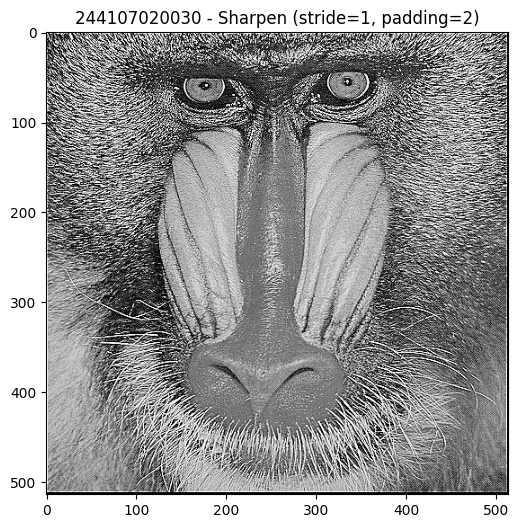

In [ ]:
# Load citra yang akan diproses dan ubah menjadi citra keabuan
img = muat_citra(CONTOH + '/mandrill.tiff', 'mandrill')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
print('Ukuran citra keabuan :', img_gray.shape)

# Menentukan kernel yang akan digunakan (image sharpen)
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

# Memanggil fungsi konvolusi sesuai contoh modul: stride=1, padding=2
hasil_sharpen = convolution2d(img_gray, kernel_sharpen, 1, 2)
print('Ukuran hasil (padding=2 menambah 2 piksel per sisi):', hasil_sharpen.shape)

plt.figure(figsize=(6, 6))
plt.imshow(np.clip(hasil_sharpen, 0, 255), cmap='gray')
plt.title(NIM + ' - Sharpen (stride=1, padding=2)')
plt.show()

**2e-2f. Tentukan kernel, panggil fungsi konvolusi**

Kernel sharpen dipanggil lewat `convolution2d(img_gray, kernel_sharpen, 1, 2)` sesuai contoh modul (stride 1, padding 2).

**3. Image Filter: Average, Low Pass, High Pass, dan filter pada tabel modul**

Semua filter dipanggil lewat `convolution2d` buatan sendiri, padding diatur setengah ukuran kernel supaya hasil sama besar dengan citra asli. Kolom terakhir tabel membuktikan hasilnya sama dengan cv.filter2D.

Filter                       Kernel   Padding  Selisih maks vs cv.filter2D
Average 3x3                  3x3      1        0.000032
Low Pass Filter              3x3      1        0.000031
High Pass Filter             3x3      1        0.000000
Sharpen                      3x3      1        0.000000
Emboss                       3x3      1        0.000000
Left Sobel Edge              3x3      1        0.000000
Canny Edge (kernel modul)    3x3      1        0.000000
21x21 Gaussian Blur          21x21    10       0.000008


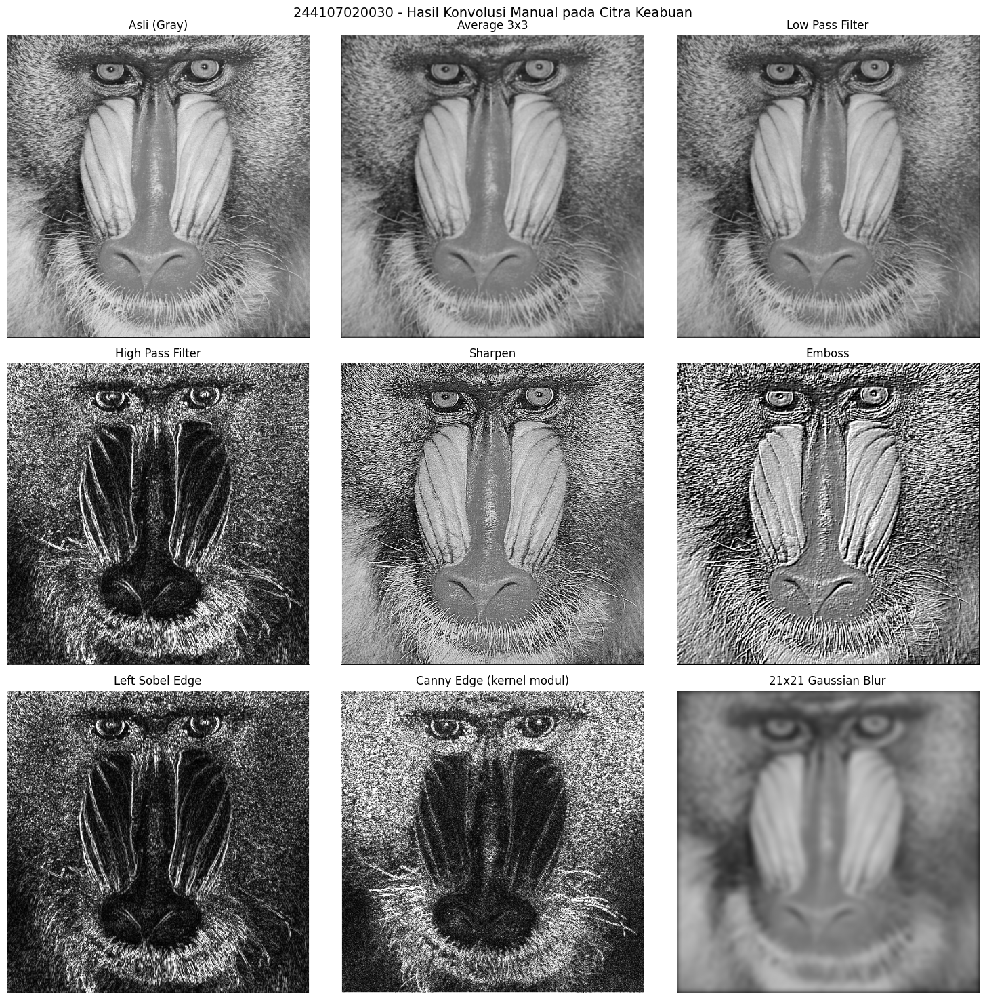

In [ ]:
def siapkan_tampil(hasil, mode):
    """clip: kembalikan ke 0-255 | abs: nilai mutlak (untuk kernel deteksi tepi)"""
    if mode == 'abs':
        hasil = np.abs(hasil)
    return np.clip(hasil, 0, 255)


# Kernel sesuai tabel modul (nama tampilan: (kernel, mode tampil))
kernel_tabel = {
    'Average 3x3'       : (np.ones((3, 3)) / 9, 'clip'),
    'Low Pass Filter'   : (np.array([[1, 1, 1], [1, 4, 1], [1, 1, 1]]) / 12, 'clip'),
    'High Pass Filter'  : (np.array([[-1, 0, 1], [-1, 0, 3], [-3, 0, 1]]), 'abs'),
    'Sharpen'           : (np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]), 'clip'),
    'Emboss'            : (np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]]), 'clip'),
    'Left Sobel Edge'   : (np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]]), 'abs'),
    'Canny Edge (kernel modul)': (np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]]), 'abs'),
}

# Kernel Gaussian 21x21 (sesuai kode di modul)
kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()
kernel_tabel['21x21 Gaussian Blur'] = (gauss_kernel, 'clip')

hasil_tabel = {}
print('%-28s %-8s %-8s %s' % ('Filter', 'Kernel', 'Padding', 'Selisih maks vs cv.filter2D'))
for nama, (k, mode) in kernel_tabel.items():
    pad = k.shape[0] // 2                                   # padding agar ukuran hasil = ukuran citra
    hasil = convolution2d(img_gray, k, stride=1, padding=pad)
    hasil_tabel[nama] = (hasil, mode)
    ref = cv.filter2D(img_gray.astype(np.float32), -1, k.astype(np.float32), borderType=cv.BORDER_CONSTANT)
    print('%-28s %-8s %-8d %.6f' % (nama, '%dx%d' % k.shape, pad, np.max(np.abs(hasil - ref))))

fig, axs = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle(NIM + ' - Hasil Konvolusi Manual pada Citra Keabuan', fontsize=14)
axs[0, 0].imshow(img_gray, cmap='gray'); axs[0, 0].set_title('Asli (Gray)')
for ax, (nama, (hasil, mode)) in zip(axs.ravel()[1:], hasil_tabel.items()):
    ax.imshow(siapkan_tampil(hasil, mode), cmap='gray', vmin=0, vmax=255)
    ax.set_title(nama)
for ax in axs.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

**Jawaban Analisa:**

Average dan Low Pass sama-sama menghaluskan citra karena bobotnya positif semua, bedanya Low Pass memberi bobot piksel pusat lebih besar (4/12) jadi detail lebih terjaga.

High Pass, Left Sobel, dan kernel Canny modul jumlah elemennya 0, sehingga area datar jadi gelap dan cuma tepi/tekstur yang menyala. Sharpen jumlah elemennya 1 jadi kecerahan tetap tapi tepi dipertegas. Emboss memperkuat perubahan cuma di satu arah sehingga terlihat seperti relief timbul.

Gaussian 21x21 mengaburkan lebih kuat dari Average 3x3 karena jendelanya jauh lebih luas, dan pinggirnya agak gelap karena padding nol.

**Tambahan: Point, Line, dan Edge Detection (teori C.3)**

Kernel Point Detection, Line Detection empat arah, Roberts, Prewitt, dan Sobel dari modul dicoba pakai fungsi konvolusi yang sama. Roberts, Prewitt, dan Sobel hasil akhirnya |gx| + |gy|.

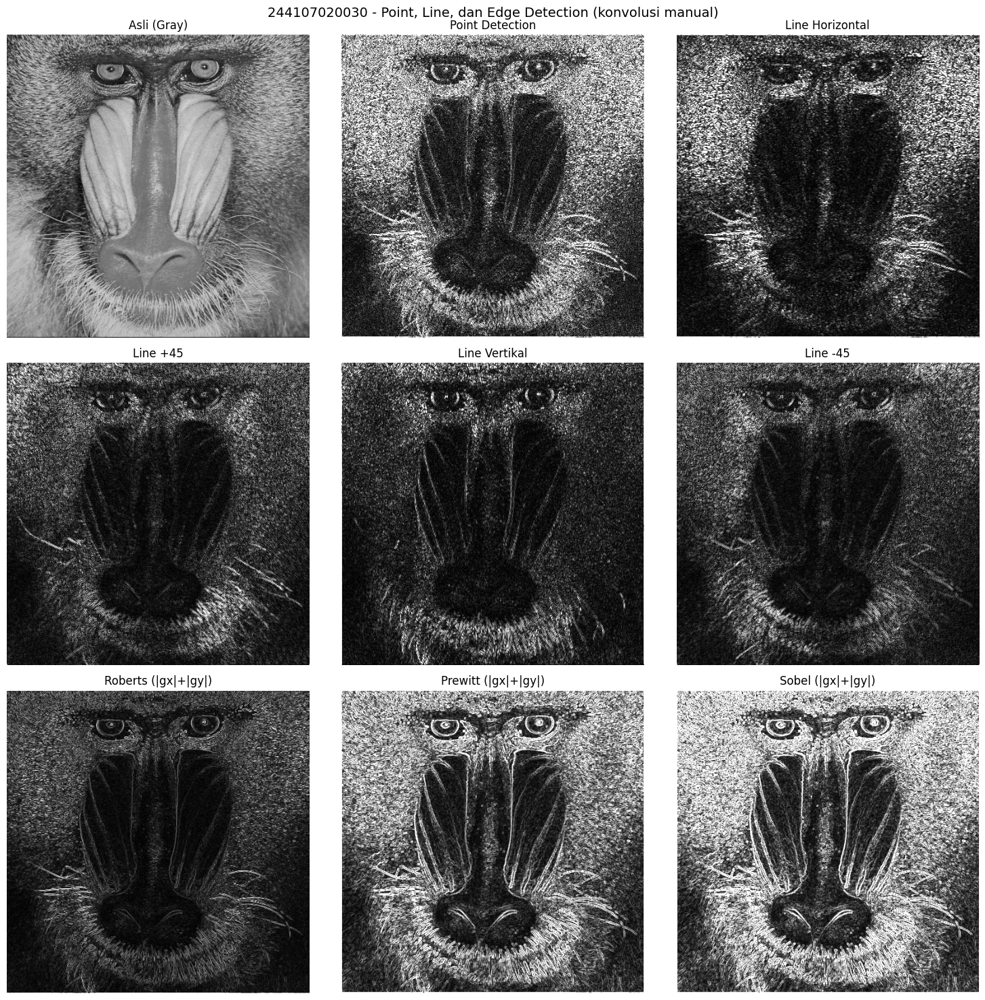

In [ ]:
# Point detection, line detection, dan edge detection (Roberts, Prewitt, Sobel) dari teori modul
kernel_deteksi = {
    'Point Detection'  : np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]]),
    'Line Horizontal'  : np.array([[-1, -1, -1], [2, 2, 2], [-1, -1, -1]]),
    'Line +45'         : np.array([[2, -1, -1], [-1, 2, -1], [-1, -1, 2]]),
    'Line Vertikal'    : np.array([[-1, 2, -1], [-1, 2, -1], [-1, 2, -1]]),
    'Line -45'         : np.array([[-1, -1, 2], [-1, 2, -1], [2, -1, -1]]),
}

# Pasangan kernel gradien (gx, gy) -> hasil akhir |gx| + |gy|
pasangan_gradien = {
    'Roberts' : (np.array([[-1, 0], [0, 1]]), np.array([[0, -1], [1, 0]])),
    'Prewitt' : (np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]]), np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])),
    'Sobel'   : (np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]), np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])),
}

panel = [('Asli (Gray)', img_gray)]
for nama, k in kernel_deteksi.items():
    panel.append((nama, np.clip(np.abs(convolution2d(img_gray, k, 1, 1)), 0, 255)))
for nama, (kx, ky) in pasangan_gradien.items():
    pad = 0 if kx.shape[0] == 2 else 1                       # Roberts 2x2 tidak diberi padding
    mag = np.abs(convolution2d(img_gray, kx, 1, pad)) + np.abs(convolution2d(img_gray, ky, 1, pad))
    panel.append((nama + ' (|gx|+|gy|)', np.clip(mag, 0, 255)))

fig, axs = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle(NIM + ' - Point, Line, dan Edge Detection (konvolusi manual)', fontsize=14)
for ax, (judul, citra) in zip(axs.ravel(), panel):
    ax.imshow(citra, cmap='gray', vmin=0, vmax=255)
    ax.set_title(judul)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Jawaban Analisa:**

Point Detection menyorot piksel yang beda jauh dari tetangganya. Line Detection cuma merespons kuat kalau ada garis yang searah kernelnya (horizontal, +45, vertikal, -45). Roberts (2x2) paling sensitif noise dan tepinya tipis, sedangkan Prewitt dan Sobel (3x3) lebih tebal dan stabil karena ada efek perataan. Sobel sedikit lebih kuat dari Prewitt karena bobot tengahnya 2.

---
# **E. Filter Library dan Filter Modern**

**Percobaan 1: Filter Gaussian, Sharpen, Canny dengan OpenCV**

cv.GaussianBlur, cv.filter2D, dan cv.Canny diterapkan pada citra RGB (lena.jpg). Fungsi show_side_by_side menampilkan hasilnya berdampingan.

[OK] lena.jpg.jpeg berhasil dimuat, ukuran (512, 512, 3)


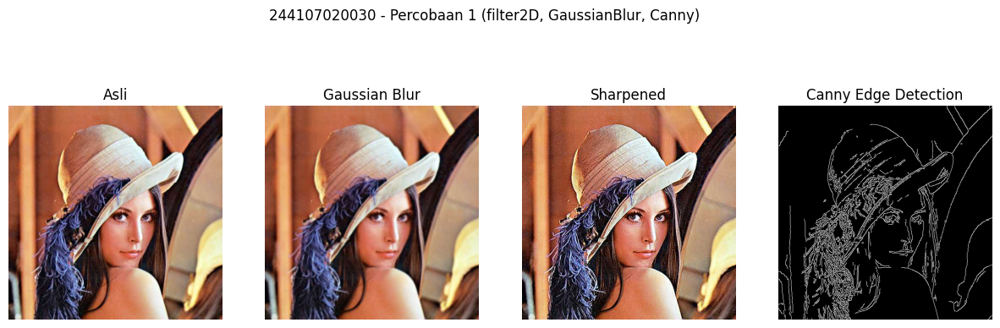

In [ ]:
# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15, 5), suptitle=None):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:  # grayscale
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.subplot(1, len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    if suptitle:
        plt.suptitle(suptitle)
    plt.show()


img_lena = muat_citra(CONTOH + '/lena.jpg', 'lena')
img = img_lena.copy()
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                  ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"],
                  suptitle=NIM + ' - Percobaan 1 (filter2D, GaussianBlur, Canny)')

**Jawaban Analisa:**

Hasil Gaussian dan sharpen konsisten dengan konvolusi manual di Bagian D. cv.Canny hasilnya citra biner garis tepi tipis, karena Canny memakai tahapan tambahan (smoothing, gradien, penipisan tepi, threshold ganda) bukan cuma satu kernel.

**Percobaan 2: Bilateral Filter dan Edge Preserving Filter**

Dua filter modern OpenCV yang menghaluskan citra tapi tetap menjaga tepi.

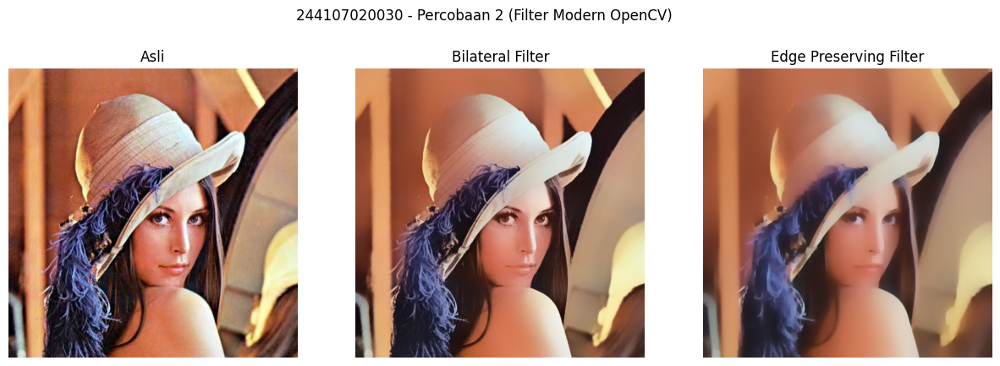

In [ ]:
#Filter Modern dari OpenCV
# Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"],
                  suptitle=NIM + ' - Percobaan 2 (Filter Modern OpenCV)')

**Jawaban Analisa:**

Bedanya dengan Gaussian, Bilateral Filter juga mempertimbangkan selisih warna jadi tepi tidak ikut diratakan. Edge Preserving Filter efeknya lebih kuat sampai mirip lukisan. Keduanya lebih lambat dibanding filter linear biasa.

**Percobaan 3: Filtering pada CNN (Feature Map)**

nn.Conv2d(1,4,kernel_size=3) dijalankan 3 kali dengan seed berbeda (sesuai instruksi modul: jalankan beberapa kali). Setelah itu bobotnya diganti manual pakai kernel Sobel, Gaussian, dan Sharpen.

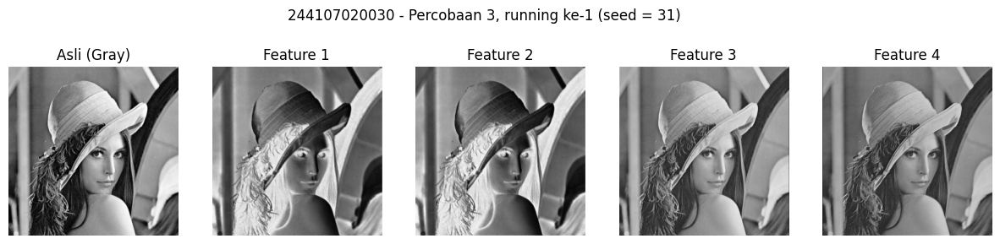

Bobot kernel Feature 1 pada running ke-1:
[[-0.18 -0.05 -0.15]
 [ 0.01 -0.2   0.02]
 [ 0.09 -0.01 -0.14]]



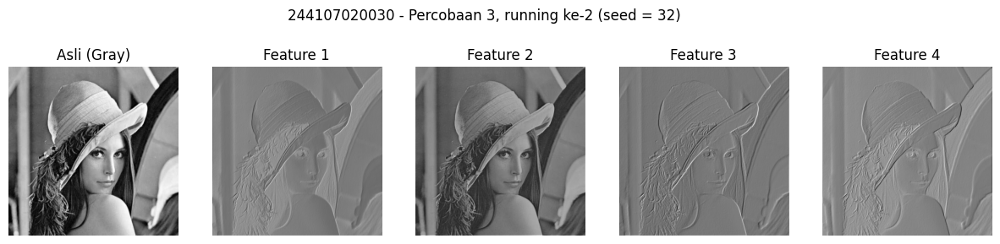

Bobot kernel Feature 1 pada running ke-2:
[[ 0.25 -0.15 -0.06]
 [ 0.19 -0.26  0.05]
 [ 0.1  -0.32  0.06]]



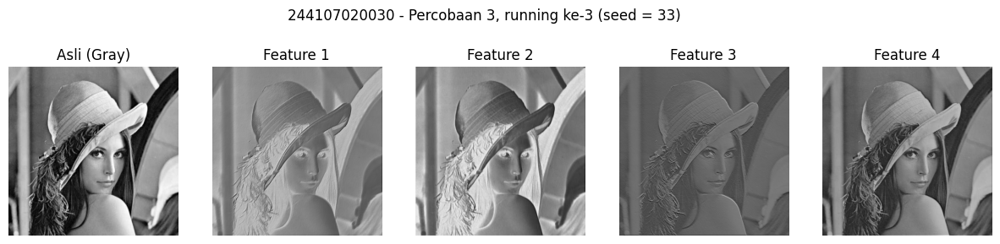

Bobot kernel Feature 1 pada running ke-3:
[[ 0.08  0.04 -0.2 ]
 [-0.11 -0.2   0.13]
 [ 0.09 -0.24  0.21]]



In [ ]:
#Filter Feature Map yang digunakan pada CNN, lakukan running code bagian ini beberapa kali dan perhatikan hasilnya
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

# Ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Jalankan 3 kali. Tiap running membuat model baru sehingga bobot kernel diacak ulang
for run in range(1, 4):
    torch.manual_seed(PARAM['seed'] + run)
    model = SimpleCNN()

    # Hasil CNN
    with torch.no_grad():
        features = model(img_tensor)

    # Visualisasi feature maps
    feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
    show_side_by_side([img_gray] + feature_maps,
                      ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))],
                      figsize=(15, 3.5),
                      suptitle=f'{NIM} - Percobaan 3, running ke-{run} (seed = {PARAM["seed"] + run})')

    print(f'Bobot kernel Feature 1 pada running ke-{run}:')
    print(np.round(model.conv1.weight[0, 0].detach().numpy(), 2))
    print()

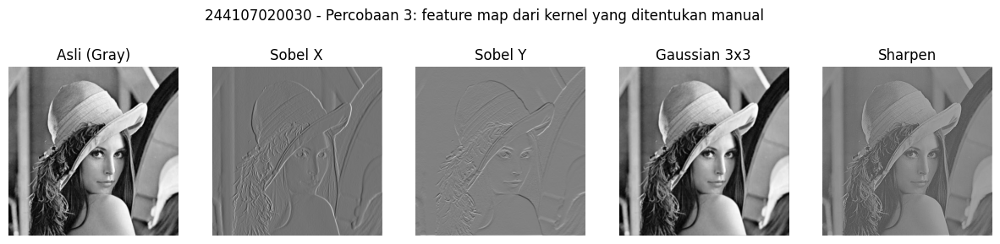

Sobel X       selisih maks CNN vs convolution2d : 4.54e-07
Sobel Y       selisih maks CNN vs convolution2d : 4.33e-07
Gaussian 3x3  selisih maks CNN vs convolution2d : 1.50e-07
Sharpen       selisih maks CNN vs convolution2d : 3.70e-07


In [ ]:
# Pembuktian: kernel CNN = kernel filter spasial. Bobot diganti manual dengan kernel dari modul
sobel_x = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])
sobel_y = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])
gauss3  = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
nama_kernel = ['Sobel X', 'Sobel Y', 'Gaussian 3x3', 'Sharpen']

model_manual = SimpleCNN()
with torch.no_grad():
    model_manual.conv1.weight.copy_(
        torch.tensor(np.stack([sobel_x, sobel_y, gauss3, sharpen]), dtype=torch.float32).unsqueeze(1))
    model_manual.conv1.bias.zero_()
    fitur = model_manual(img_tensor)[0].numpy()

show_side_by_side([img_gray] + [fitur[i] for i in range(4)],
                  ['Asli (Gray)'] + nama_kernel, figsize=(15, 3.5),
                  suptitle=NIM + ' - Percobaan 3: feature map dari kernel yang ditentukan manual')

# Bandingkan dengan fungsi convolution2d buatan sendiri (Conv2d PyTorch = korelasi, tanpa flip kernel)
for i, k in enumerate([sobel_x, sobel_y, gauss3, sharpen]):
    manual = convolution2d(img_gray / 255.0, k, stride=1, padding=1)
    print('%-13s selisih maks CNN vs convolution2d : %.2e' % (nama_kernel[i], np.max(np.abs(fitur[i] - manual))))

**Jawaban Analisa:**

Tiap running menghasilkan feature map berbeda karena bobot Conv2d diinisialisasi acak (model belum dilatih). Waktu bobot diganti manual pakai kernel Sobel/Gaussian/Sharpen, hasil CNN sama persis dengan fungsi convolution2d buatan sendiri (selisih mendekati 0), karena nn.Conv2d juga melakukan korelasi tanpa flip kernel.

Beda utamanya: kernel filter tradisional dirancang manusia, kernel CNN dipelajari lewat training. Satu lapisan bisa punya banyak kernel sekaligus (di sini 4), jadi satu citra menghasilkan beberapa feature map berbeda.

**Percobaan 4: Beauty Filter dan Old/Vintage Filter**

Beauty: Bilateral Filter (haluskan kulit) + unsharp masking (pertajam) + brightness/contrast. Vintage: transformasi sepia + vignette (kernel Gaussian) + noise/grain.

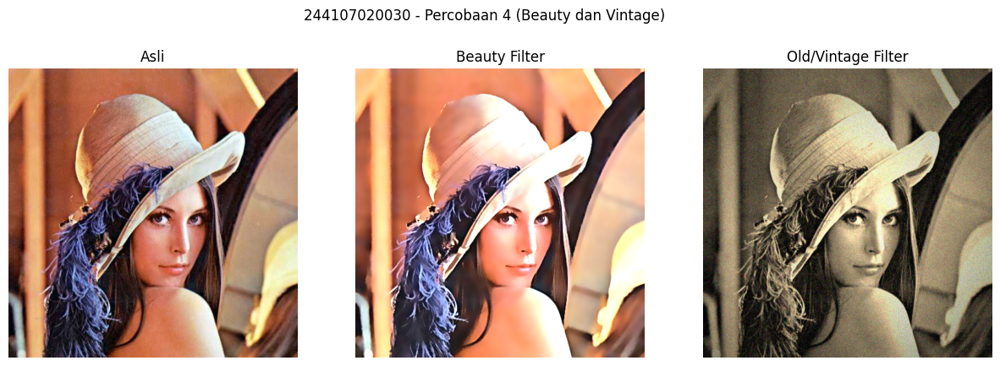

In [ ]:
# Bagian 1: Beauty Filter
# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2  # contrast
beta = 15    # brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

# Bagian 2: Old/Vintage Filter
# Step 1: Sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:, :, i] = vignette[:, :, i] * mask

# Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, old_img],
                  ["Asli", "Beauty Filter", "Old/Vintage Filter"],
                  suptitle=NIM + ' - Percobaan 4 (Beauty dan Vintage)')

**Jawaban Analisa:**

Beauty Filter menghaluskan kulit tanpa membuat kontur buram (Bilateral Filter), lalu unsharp masking mengembalikan ketajaman mata/rambut. Vintage: sepia memberi tone kecokelatan, vignette menggelapkan sisi citra, noise Gaussian menambah kesan foto lama (hasil grain berubah tiap running karena acak).

**Percobaan 5: Filter Anime / Cartoon**

Tepi dideteksi pakai Median Blur + Adaptive Threshold, warna dihaluskan Bilateral Filter, digabung dengan cv.bitwise_and.

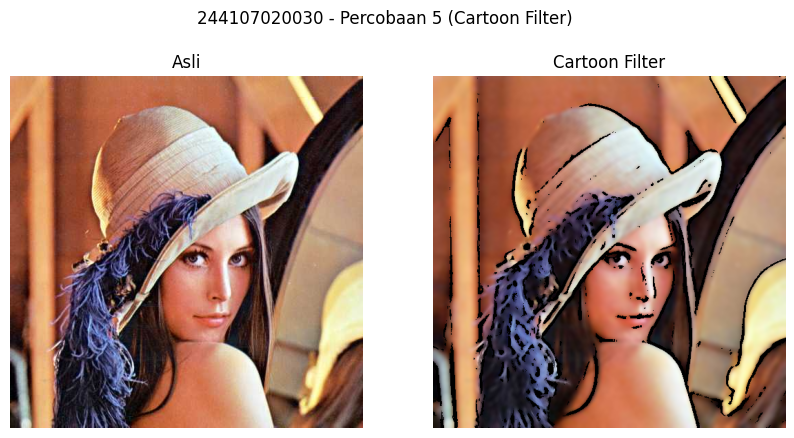

In [ ]:
#Filter Anime / Cartoon
# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9, 9)

# Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

# Tampilkan
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"],
                  figsize=(10, 5), suptitle=NIM + ' - Percobaan 5 (Cartoon Filter)')

**Jawaban Analisa:**

Adaptive Threshold pakai ambang lokal jadi tepi tetap terdeteksi walau pencahayaan tidak merata. Median Blur sebelum threshold mengurangi noise supaya garis tidak putus-putus. Bitwise_and menggambar garis hitam di atas warna yang sudah rata sehingga terlihat seperti kartun.

**Percobaan 6-7: Filter Malam, Filter Pagi, dan Kabut**

Malam: kontras turun, brightness negatif, bias biru, glow (filter2D kernel rata-rata 15x15). Pagi: kontras turun, brightness naik, warm tone oranye, kabut (blur filter2D + lapisan putih).

[OK] djawatan.jpg.jpeg berhasil dimuat, ukuran (720, 1080, 3)


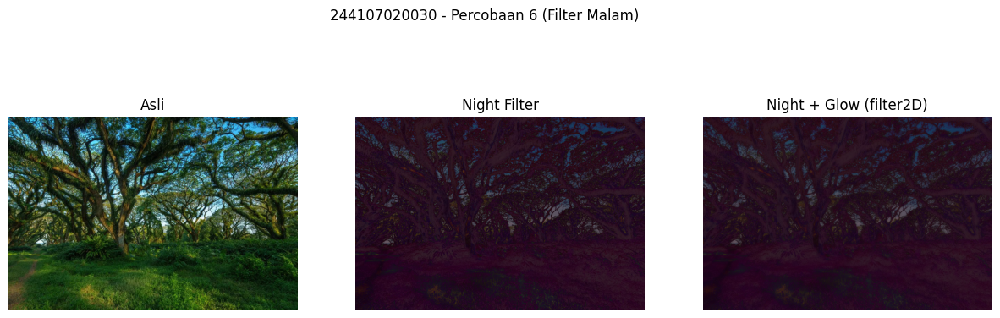

In [ ]:
#Night Filter
img_alam = muat_citra(CONTOH + '/djawatan.jpg', 'alam')

# Step 1: Gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(img_alam, alpha=0.6, beta=-40)

# Step 2: Tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100))  # BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img_alam, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (filter2D)"],
                  suptitle=NIM + ' - Percobaan 6 (Filter Malam)')

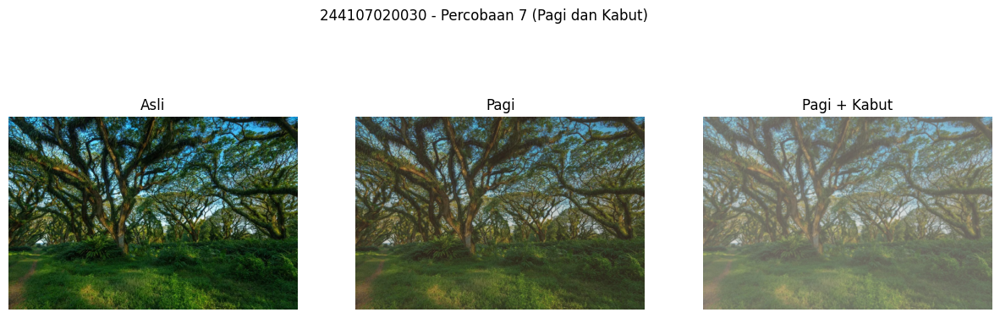

In [ ]:
#Filter Suasana pagi dan Kabut
# Step 1: Kurangi kontras dan cerahkan citra
alpha = 0.9   # contrast
beta = 20     # brightness
soft = cv.convertScaleAbs(img_alam, alpha=alpha, beta=beta)

# Step 2: Tambahkan warm tone kemerahan/oranye
warm_tint = np.full_like(soft, (40, 70, 120))  # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# Step 3: Tambahkan haze atau kabut tipis dengan filter2D
# Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T  # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img_alam, pagi, kabut],
                  ["Asli", "Pagi", "Pagi + Kabut"],
                  suptitle=NIM + ' - Percobaan 7 (Pagi dan Kabut)')

**Jawaban Analisa:**

Filter Malam (alpha 0,6 beta -40) menggelapkan citra, bias biru memberi nuansa malam. Filter Pagi kontras turun brightness naik untuk kesan lembut, warm tone oranye untuk kesan matahari pagi, dan kabut dibuat dari blur ringan + lapisan putih 30% yang mengurangi kontras area gelap.

---
# **Tugas Praktikum**

Fungsi bantu: penghitung PSNR dan penampil citra penuh + potongan area zoom, dipakai di ketiga tugas.

In [ ]:
def hitung_psnr(img1, img2):
    mse = np.mean((img1.astype(np.float64) - img2.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf'), mse
    return 20 * math.log10(255.0 / math.sqrt(mse)), mse


def crop_zoom(img, y0, x0, ukuran=64):
    """Memotong area kecil untuk diperbesar agar detail noise/tepi terlihat jelas."""
    return img[y0:y0 + ukuran, x0:x0 + ukuran]


def tampil_dua_baris(citra, judul, y0, x0, suptitle, ukuran=64):
    """Baris atas: citra penuh. Baris bawah: potongan area yang diperbesar."""
    n = len(citra)
    fig, axs = plt.subplots(2, n, figsize=(4.2 * n, 8.6))
    fig.suptitle(suptitle, fontsize=13)
    for i, (c, t) in enumerate(zip(citra, judul)):
        axs[0, i].imshow(np.clip(c, 0, 255), cmap='gray', vmin=0, vmax=255)
        axs[0, i].set_title(t, fontsize=10)
        axs[0, i].add_patch(plt.Rectangle((x0, y0), ukuran, ukuran, fill=False, edgecolor='red', linewidth=1.5))
        axs[1, i].imshow(np.clip(crop_zoom(c, y0, x0, ukuran), 0, 255), cmap='gray', vmin=0, vmax=255,
                         interpolation='nearest')
        axs[1, i].set_title('Zoom area merah', fontsize=10)
        axs[0, i].axis('off'); axs[1, i].axis('off')
    plt.tight_layout()
    plt.show()

**Tugas 1: Mean Filter vs Median Filter pada Noise Salt and Pepper**

a. Tambahkan noise Salt and Pepper ke citra keabuan (kepadatan sesuai PARAM['noise']).

b. Terapkan Mean Filter 3x3 (lewat convolution2d) dan Median Filter 3x3 (dibuat manual), dibandingkan dengan cv.blur dan cv.medianBlur.

c. Amati secara visual (termasuk zoom) dan metrik PSNR/MAE.

Kepadatan noise PARAM['noise'] = 0.05 -> 13133 piksel rusak dari 262144 (5.01%)
Selisih maks mean   manual vs cv.blur       : 0
Selisih maks median manual vs cv.medianBlur : 0


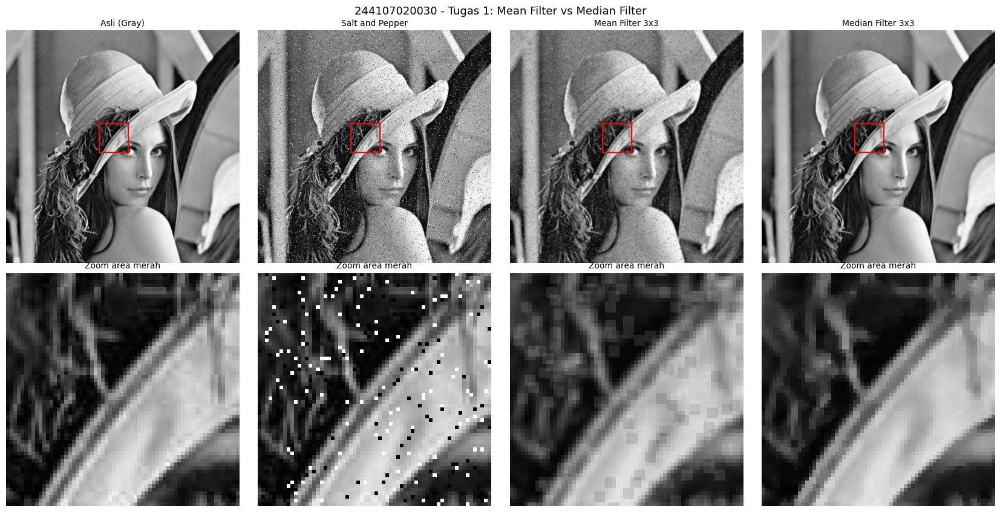

In [ ]:
# a. Citra keabuan + noise Salt and Pepper
gray_asli = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)

def tambah_salt_pepper(gray, kepadatan, seed):
    """Sebagian piksel diganti 0 (pepper/hitam) dan 255 (salt/putih), masing-masing separuh kepadatan."""
    rng = np.random.default_rng(seed)
    acak = rng.random(gray.shape)
    noisy = gray.copy()
    noisy[acak < kepadatan / 2] = 0
    noisy[acak > 1 - kepadatan / 2] = 255
    return noisy, (acak < kepadatan / 2) | (acak > 1 - kepadatan / 2)

gray_noisy, mask_noise = tambah_salt_pepper(gray_asli, PARAM['noise'], PARAM['seed'])
print(f"Kepadatan noise PARAM['noise'] = {PARAM['noise']} -> {mask_noise.sum()} piksel rusak "
      f"dari {gray_asli.size} ({mask_noise.mean() * 100:.2f}%)")

# b. Mean Filter 3x3 memakai convolution2d buatan sendiri, Median Filter 3x3 dibuat manual
def mean_filter(gray, ksize=3):
    p = ksize // 2
    tepi_replikasi = np.pad(gray, p, mode='edge')            # pinggir diduplikasi (solusi ke-2 modul)
    kernel_mean = np.ones((ksize, ksize)) / (ksize * ksize)
    return np.clip(np.round(convolution2d(tepi_replikasi, kernel_mean, 1, 0)), 0, 255).astype(np.uint8)

def median_filter(gray, ksize=3):
    p = ksize // 2
    padded = np.pad(gray, p, mode='edge')
    H, W = gray.shape
    # kumpulkan seluruh tetangga tiap piksel, lalu ambil nilai tengah setelah diurutkan
    tetangga = np.stack([padded[k1:k1 + H, k2:k2 + W] for k1 in range(ksize) for k2 in range(ksize)], axis=0)
    return np.median(tetangga, axis=0).astype(np.uint8)

hasil_mean   = mean_filter(gray_noisy, 3)
hasil_median = median_filter(gray_noisy, 3)

# Verifikasi terhadap fungsi OpenCV (hanya sebagai pembanding)
print('Selisih maks mean   manual vs cv.blur       :', int(np.max(np.abs(
    hasil_mean.astype(int) - cv.blur(gray_noisy, (3, 3), borderType=cv.BORDER_REPLICATE).astype(int)))))
print('Selisih maks median manual vs cv.medianBlur :', int(np.max(np.abs(
    hasil_median.astype(int) - cv.medianBlur(gray_noisy, 3).astype(int)))))

# Tampilan visual
tampil_dua_baris([gray_asli, gray_noisy, hasil_mean, hasil_median],
                 ['Asli (Gray)', 'Salt and Pepper', 'Mean Filter 3x3', 'Median Filter 3x3'],
                 y0=int(0.40 * gray_asli.shape[0]), x0=int(0.40 * gray_asli.shape[1]),
                 suptitle=NIM + ' - Tugas 1: Mean Filter vs Median Filter')

In [ ]:
# Evaluasi kuantitatif terhadap citra asli (tanpa noise)
print('%-20s %10s %10s %14s %14s' % ('Citra', 'PSNR (dB)', 'MAE total', 'MAE p.noise', 'MAE p.bersih'))
hasil_metrik = {}
for nama, c in [('Noisy (tanpa filter)', gray_noisy), ('Mean Filter 3x3', hasil_mean), ('Median Filter 3x3', hasil_median)]:
    selisih = np.abs(c.astype(np.float64) - gray_asli.astype(np.float64))
    psnr, _ = hitung_psnr(gray_asli, c)
    hasil_metrik[nama] = (psnr, selisih.mean(), selisih[mask_noise].mean(), selisih[~mask_noise].mean())
    print('%-20s %10.2f %10.2f %14.2f %14.2f' % ((nama, ) + hasil_metrik[nama]))

print()
print('Catatan: "p.noise" = piksel yang tadinya dirusak noise, "p.bersih" = piksel yang tadinya tidak rusak.')
if hasil_metrik['Median Filter 3x3'][0] > hasil_metrik['Mean Filter 3x3'][0]:
    print('=> PSNR Median Filter lebih tinggi daripada Mean Filter, sehingga hasil Median lebih dekat ke citra asli.')
else:
    print('=> PSNR Mean Filter lebih tinggi pada citra ini, periksa kembali kepadatan noise dan hasil visualnya.')

Citra                 PSNR (dB)  MAE total    MAE p.noise   MAE p.bersih
Noisy (tanpa filter)      18.01       6.42         128.11           0.00
Mean Filter 3x3           25.84       8.09          17.62           7.58
Median Filter 3x3         33.12       2.36           3.97           2.27

Catatan: "p.noise" = piksel yang tadinya dirusak noise, "p.bersih" = piksel yang tadinya tidak rusak.
=> PSNR Median Filter lebih tinggi daripada Mean Filter, sehingga hasil Median lebih dekat ke citra asli.


**Jawaban Analisa (poin c):**

Noise Salt and Pepper itu piksel pencilan bernilai 0 atau 255. Dari hasil running, citra ber-noise sebelum difilter PSNR-nya cuma 18,01 dB dengan MAE piksel noise 128,11.

Mean Filter merata-ratakan seluruh 9 piksel jendela, jadi noise tidak hilang, cuma menyebar jadi bercak abu-abu yang lebih lebar (kelihatan di zoom). PSNR-nya naik jadi 25,84 dB, tapi MAE piksel bersih malah naik dari 0 jadi 7,58, artinya piksel yang tadinya bersih ikut berubah dan tepinya jadi buram.

Median Filter mengurutkan 9 nilai lalu ambil nilai tengah. Nilai 0/255 selalu di ujung urutan sehingga terbuang selama noise kurang dari separuh jendela. PSNR-nya jadi paling tinggi, 33,12 dB, dan MAE piksel bersihnya cuma 2,27, jauh lebih kecil dari Mean Filter, jadi tepi tetap tajam dan piksel bersih hampir tidak berubah.

Kesimpulan: Median Filter jelas lebih efektif untuk noise Salt and Pepper karena PSNR lebih tinggi dan MAE lebih kecil di kedua jenis piksel (noise maupun bersih). Mean Filter lebih cocok untuk noise yang menyebar merata seperti Gaussian, bukan noise impulsif seperti ini.

**Tugas 2: Pemilihan Ukuran Kernel Sharpening (3x3 vs 5x5)**

a. Buat kernel sharpen 3x3 (dari modul) dan 5x5 (unsharp masking: 2×impuls - Gaussian 5x5).

b. Terapkan pada citra blur (Gaussian sigma = PARAM['blur']) + noise ringan.

c. Evaluasi kejelasan tepi vs penguatan noise (dipisah karena konvolusi bersifat linear).

Jumlah elemen kernel 3x3 : 1.0
Jumlah elemen kernel 5x5 : 1.0
Kernel 5x5 x 256:
 [[ -1  -4  -6  -4  -1]
 [ -4 -16 -24 -16  -4]
 [ -6 -24 476 -24  -6]
 [ -4 -16 -24 -16  -4]
 [ -1  -4  -6  -4  -1]]


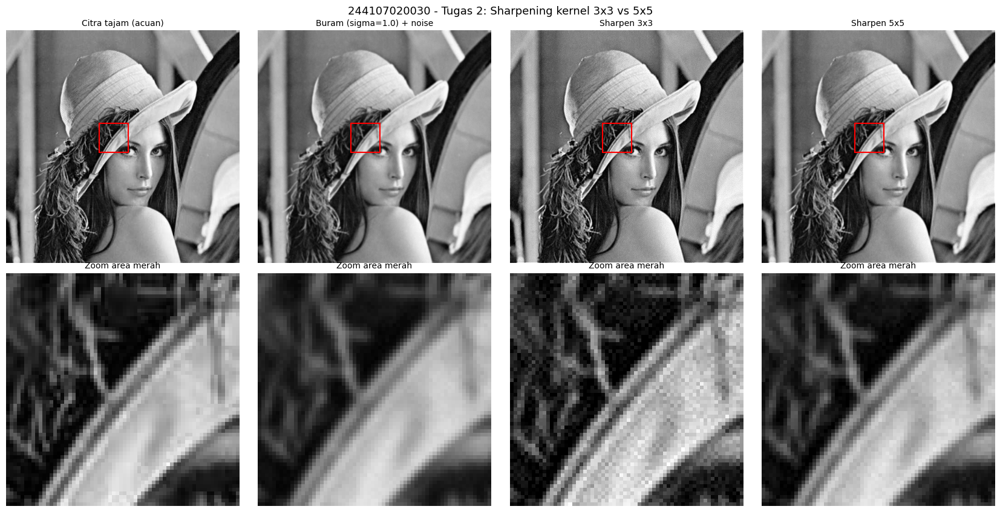

In [ ]:
# a. Kernel penajaman 3x3 dan 5x5
# 3x3: kernel sharpening dari modul (jumlah elemen = 1)
kernel_3x3 = np.array([[ 0, -1,  0],
                       [-1,  5, -1],
                       [ 0, -1,  0]], dtype=np.float64)

# 5x5: unsharp masking = 2 x (impuls) - (Gaussian 5x5 dari teori modul), jumlah elemen = 1
gauss_5x5 = np.array([[1,  4,  6,  4, 1],
                      [4, 16, 24, 16, 4],
                      [6, 24, 36, 24, 6],
                      [4, 16, 24, 16, 4],
                      [1,  4,  6,  4, 1]]) / 256
impuls = np.zeros((5, 5)); impuls[2, 2] = 1
kernel_5x5 = 2 * impuls - gauss_5x5

print('Jumlah elemen kernel 3x3 :', kernel_3x3.sum())
print('Jumlah elemen kernel 5x5 :', round(kernel_5x5.sum(), 6))
print('Kernel 5x5 x 256:\n', np.round(kernel_5x5 * 256).astype(int))

# b. Citra yang sedikit buram (Gaussian blur) ditambah noise sensor ringan agar mirip foto nyata
gray_tajam = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)
rng = np.random.default_rng(PARAM['seed'])
buram_bersih = cv.GaussianBlur(gray_tajam, (0, 0), PARAM['blur']).astype(np.float64)   # buram tanpa noise
derau = rng.normal(0, 2.0, gray_tajam.shape)                                          # noise Gaussian sigma = 2
buram = np.clip(np.round(buram_bersih + derau), 0, 255)                               # citra uji

hasil_3x3 = convolution2d(buram, kernel_3x3, 1, 1)
hasil_5x5 = convolution2d(buram, kernel_5x5, 1, 2)

tampil_dua_baris([gray_tajam, buram, hasil_3x3, hasil_5x5],
                 ['Citra tajam (acuan)', f"Buram (sigma={PARAM['blur']}) + noise", 'Sharpen 3x3', 'Sharpen 5x5'],
                 y0=int(0.40 * gray_tajam.shape[0]), x0=int(0.40 * gray_tajam.shape[1]),
                 suptitle=NIM + ' - Tugas 2: Sharpening kernel 3x3 vs 5x5')

In [ ]:
# c. Evaluasi: kejelasan tepi vs noise. Karena konvolusi bersifat linear:
#    hasil(citra buram + noise) = hasil(citra buram bersih) + hasil(noise saja)
#    sehingga kejelasan tepi dan penguatan noise bisa diukur terpisah.
m = 3  # potong pinggir agar efek padding nol tidak ikut terhitung

def tenengrad(citra):
    """Kejelasan tepi = rerata besar gradien Sobel (makin besar makin tajam)."""
    gx = cv.Sobel(citra.astype(np.float64), cv.CV_64F, 1, 0, ksize=3)
    gy = cv.Sobel(citra.astype(np.float64), cv.CV_64F, 0, 1, ksize=3)
    return np.mean(np.sqrt(gx ** 2 + gy ** 2)[m:-m, m:-m])

acuan_tepi = tenengrad(gray_tajam)
print('Kejelasan tepi citra tajam (acuan)      : %.2f' % acuan_tepi)
print('Kejelasan tepi citra buram (tanpa filter): %.2f  (%.0f%% dari acuan)' % (
    tenengrad(buram_bersih), 100 * tenengrad(buram_bersih) / acuan_tepi))
print()
print('%-14s %16s %16s %14s %12s' % ('Kernel', 'Tepi (% acuan)', 'Std noise keluar', 'Gain noise', 'PSNR (dB)'))

hasil_eval = {}
for nama, k, pad in [('Sharpen 3x3', kernel_3x3, 1), ('Sharpen 5x5', kernel_5x5, 2)]:
    tepi_bersih = convolution2d(buram_bersih, k, 1, pad)     # efek pada tepi (tanpa noise)
    noise_keluar = convolution2d(derau, k, 1, pad)           # efek pada noise saja
    hasil_penuh = np.clip(convolution2d(buram, k, 1, pad), 0, 255)
    persen_tepi = 100 * tenengrad(tepi_bersih) / acuan_tepi
    std_noise = noise_keluar[m:-m, m:-m].std()
    gain = std_noise / derau.std()
    psnr, _ = hitung_psnr(gray_tajam[m:-m, m:-m], hasil_penuh[m:-m, m:-m])
    hasil_eval[nama] = (persen_tepi, std_noise, gain, psnr)
    print('%-14s %15.1f%% %16.2f %13.2fx %12.2f' % (nama, persen_tepi, std_noise, gain, psnr))

psnr_buram, _ = hitung_psnr(gray_tajam[m:-m, m:-m], buram[m:-m, m:-m])
print('%-14s %16s %16s %14s %12.2f' % ('Buram (asli)', '-', '%.2f' % derau.std(), '1.00x', psnr_buram))

print()
print('Gain noise teoretis = akar(jumlah kuadrat elemen kernel): 3x3 = %.2fx, 5x5 = %.2fx' % (
    np.sqrt(np.sum(kernel_3x3 ** 2)), np.sqrt(np.sum(kernel_5x5 ** 2))))

terbaik = max(hasil_eval, key=lambda n: hasil_eval[n][3])
print(f'=> Kernel dengan PSNR tertinggi terhadap citra tajam: {terbaik}')

Kejelasan tepi citra tajam (acuan)      : 63.29
Kejelasan tepi citra buram (tanpa filter): 47.51  (75% dari acuan)

Kernel           Tepi (% acuan) Std noise keluar     Gain noise    PSNR (dB)
Sharpen 3x3              106.9%            10.78          5.38x        26.99
Sharpen 5x5               87.4%             3.75          1.87x        32.42
Buram (asli)                  -             2.00          1.00x        30.87

Gain noise teoretis = akar(jumlah kuadrat elemen kernel): 3x3 = 5.39x, 5x5 = 1.87x
=> Kernel dengan PSNR tertinggi terhadap citra tajam: Sharpen 5x5


**Jawaban Analisa (poin c):**

Dari hasil running, kejelasan tepi citra tajam acuan sebesar 63,29, sedangkan citra buram sebelum difilter cuma 47,51 (75% dari acuan).

Kernel 3x3 menaikkan kejelasan tepi jadi 106,9% dari acuan, artinya menajamkan sangat agresif sampai melebihi citra aslinya sendiri (rawan over-sharpening/halo), tapi noise ikut diperkuat 5,38 kali sehingga PSNR-nya malah turun jadi 26,99 dB, lebih rendah dari citra buram yang belum diapa-apakan (30,87 dB).

Kernel 5x5 kejelasan tepinya 87,4% dari acuan, jadi lebih lembut, tapi noise cuma diperkuat 1,87 kali dan PSNR-nya naik jadi 32,42 dB, paling tinggi di antara ketiganya.

Kesimpulan: untuk pemakaian sehari-hari (foto kamera/ponsel yang hampir selalu ada noise), kernel 5x5 lebih optimal karena PSNR-nya paling tinggi, artinya paling dekat ke citra tajam sebenarnya meskipun tepinya tidak setajam 3x3. Kernel 3x3 rawan dipakai kalau citranya sudah ada noise sedikit saja, karena PSNR-nya malah lebih jelek dari tidak difilter sama sekali. Kekurangan 5x5 cuma di biaya komputasi yang lebih besar (25 vs 9 perkalian per piksel).

**Tugas 3: Filter Kartun Sederhana**

Fungsi `kartun(image)` menggabungkan:
a. Bilateral Filter (ratakan warna) + Adaptive Threshold/Canny Edge (deteksi tepi) + bitwise_and/perkalian piksel (gabungkan).

b. Tampilkan citra asli dan hasil kartun bersebelahan.

Selisih maks bitwise_and vs perkalian piksel : 0
blockSize Adaptive Threshold (PARAM['blok']) : 7


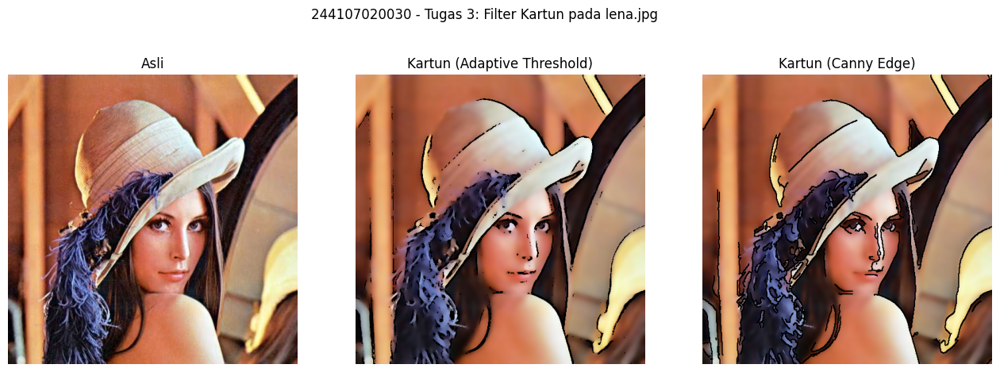

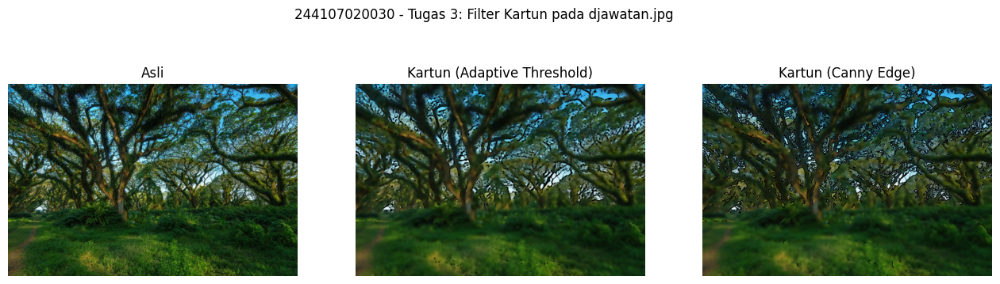

In [ ]:
def kartun(image, metode='adaptive', operasi='logika', blok=PARAM['blok']):
    """Filter kartun sederhana.
    image  : citra BGR
    metode : 'adaptive' (Adaptive Thresholding) atau 'canny' (Canny Edge) untuk garis tepi
    operasi: 'logika' (bitwise AND) atau 'kali' (perkalian piksel) untuk menggabungkan warna dan garis"""
    # 1. Penghalusan warna dengan Bilateral Filter (diulang 3x agar area warna menjadi rata)
    warna = image.copy()
    for _ in range(3):
        warna = cv.bilateralFilter(warna, d=9, sigmaColor=75, sigmaSpace=75)

    # 2. Deteksi garis tepi (garis = hitam, latar = putih)
    abu = cv.medianBlur(cv.cvtColor(image, cv.COLOR_BGR2GRAY), 7)
    if metode == 'adaptive':
        tepi = cv.adaptiveThreshold(abu, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, blok, 9)
    elif metode == 'canny':
        garis = cv.Canny(abu, 80, 160)
        garis = cv.dilate(garis, np.ones((2, 2), np.uint8))   # garis ditebalkan sedikit
        tepi = 255 - garis
    else:
        raise ValueError("metode harus 'adaptive' atau 'canny'")
    tepi_bgr = cv.cvtColor(tepi, cv.COLOR_GRAY2BGR)

    # 3. Penggabungan warna halus dan garis tepi
    if operasi == 'logika':
        return cv.bitwise_and(warna, tepi_bgr)
    return (warna.astype(np.float32) * (tepi_bgr / 255.0)).astype(np.uint8)


kartun_adaptive = kartun(img_lena, metode='adaptive')
kartun_canny    = kartun(img_lena, metode='canny')

# Pembuktian: operasi logika AND dan perkalian piksel menghasilkan citra yang sama
kartun_kali = kartun(img_lena, metode='adaptive', operasi='kali')
print('Selisih maks bitwise_and vs perkalian piksel :', int(np.max(np.abs(kartun_adaptive.astype(int) - kartun_kali.astype(int)))))
print(f"blockSize Adaptive Threshold (PARAM['blok']) : {PARAM['blok']}")

# b. Tampilkan citra asli dan hasil kartun bersebelahan
show_side_by_side([img_lena, kartun_adaptive, kartun_canny],
                  ['Asli', 'Kartun (Adaptive Threshold)', 'Kartun (Canny Edge)'],
                  figsize=(16, 5.5), suptitle=NIM + ' - Tugas 3: Filter Kartun pada lena.jpg')

show_side_by_side([img_alam, kartun(img_alam, 'adaptive'), kartun(img_alam, 'canny')],
                  ['Asli', 'Kartun (Adaptive Threshold)', 'Kartun (Canny Edge)'],
                  figsize=(16, 4.5), suptitle=NIM + ' - Tugas 3: Filter Kartun pada djawatan.jpg')

**Jawaban Analisa:**

Bilateral Filter (diulang 3x) meratakan warna per area tapi tidak menembus tepi kontras, jadi hasilnya blok warna rata mirip kartun. Adaptive Threshold pakai ambang lokal (tahan terhadap pencahayaan tidak merata), hasilnya garis lebih tebal seperti coretan; Canny hasilnya garis tipis jadi ditebalkan dengan cv.dilate. Median Blur dipakai dulu supaya tekstur kecil tidak ikut jadi garis.

Bitwise_and (mask 0/255) dan perkalian piksel (mask 0/1) memberi hasil identik, terbukti dari selisih maksimum 0.

---
# **Kesimpulan**

1. Konvolusi 2D (kernel, stride, padding) berhasil dibuat tanpa library, hasilnya sama persis dengan cv.filter2D.
2. Jenis efek filter ditentukan jumlah elemen kernel: jumlah 1 + bobot positif = menghaluskan, jumlah 1 + pusat besar = menajamkan, jumlah 0 = menyorot tepi.
3. Efek populer (beauty, vintage, kartun, malam, pagi, kabut) bisa dibentuk dari kombinasi filter tradisional; kernel CNN pada dasarnya sama dengan kernel filter spasial, bedanya nilainya dipelajari lewat training.
4. Median Filter lebih efektif dari Mean Filter untuk noise Salt and Pepper karena mengabaikan nilai pencilan.
5. Ukuran kernel sharpening memengaruhi keseimbangan antara ketajaman tepi dan penguatan noise.